# 01. Подготовка геопространственной базы

**Цель:** собрать единую таблицу «субъект РФ × 4 показателя цифрового развития за 2021 год + граница субъекта»
и проверить ее корректность: идентификаторы, систему координат, геометрию, пропуски, сопоставимость.

Источники:
- статистика — сборник Росстата «Регионы России. Социально-экономические показатели» в машиночитаемом виде,
  проект «Если быть точным»: https://github.com/tochno-st/regions_collection (v1.0, раздел 17 «ИКТ»);
- границы субъектов РФ — OpenStreetMap, набор https://github.com/timurkanaz/Russia_geojson_OSM
  (`Russia_regions.geojson`, 85 субъектов, EPSG:4326, Polygon/MultiPolygon).

In [1]:
import sys, json, subprocess
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import geopandas as gpd
import yaml
import shapely
import matplotlib.pyplot as plt

from src.common import (RAW, PROCESSED, MAPS, CRS_AEA, INDICATORS, FEATURES, LABELS, YEAR,
                        MISSING_CODE, POPULATION_CODE, SOURCES, download, connected_queen)

pd.set_option("display.width", 200)
SRC = RAW / "_source"          # кэш тяжелых исходных файлов (в git не хранится, см. README)

## 1. Загрузка исходных файлов
Архив сборника (RAR, 6,6 МБ) содержит CSV по 21 разделу (UTF-8, разделитель `;`). Если раздела нет в кэше,
архив скачивается и распаковывается (`tar` из Windows 10+/libarchive или `7z`).

In [2]:
def ensure_sections():
    need = [SRC / "section_17.csv", SRC / "section_01.csv"]
    if all(p.exists() for p in need):
        return
    rar = download(SOURCES["regions_collection_rar"], SRC / "data_regions_collection_102_v1.0.rar")
    for cmd in (["tar", "-xf", str(rar), "-C", str(SRC)], ["7z", "x", "-y", f"-o{SRC}", str(rar)]):
        try:
            subprocess.run(cmd, check=True)
            return
        except Exception:
            continue
    raise RuntimeError("Распакуйте архив вручную в data/raw/_source")

ensure_sections()
download(SOURCES["regions_etalon"], SRC / "regions_etalon.yaml")
download(SOURCES["boundaries"], SRC / "boundaries" / "Russia_regions.geojson")
sorted(p.name for p in SRC.rglob("*.*"))

['Russia_regions.geojson',
 'regions_etalon.yaml',
 'section_01.csv',
 'section_17.csv']

## 2. Показатели за 2021 год
Отбираем 4 кода раздела 17 и численность населения (код 01010000, нужна только как ограничение метода Max-p).
Код пропуска в сборнике — `-99999999`.

In [3]:
dtype = {"indicator_code": str, "object_okato": str, "object_oktmo": str}
s17 = pd.read_csv(SRC / "section_17.csv", sep=";", dtype=dtype)
ind = s17[s17.indicator_code.isin(INDICATORS)].copy()

# выгрузка исходных строк по выбранным показателям (все годы и уровни) — «сырые» таблицы проекта
ind.to_csv(RAW / "indicators_17_ict_all_years.csv", index=False, encoding="utf-8")
(ind.groupby(["indicator_code", "indicator_name", "indicator_unit"]).size()
    .rename("rows").reset_index())

,indicator_code,indicator_name,indicator_unit,rows
0,17080100,Использование персональных компьютеров и сети ...,по данным выборочного обследования населения п...,2112
1,17080200,Использование персональных компьютеров и сети ...,по данным выборочного обследования населения п...,2112
2,17080300,Использование персональных компьютеров и сети ...,по данным выборочного обследования населения п...,2112
3,17090200,Использование сети интернет населением: Населе...,по данным выборочного обследования населения п...,2112


In [4]:
s01 = pd.read_csv(SRC / "section_01.csv", sep=";", dtype=dtype)
pop = s01[(s01.indicator_code == POPULATION_CODE) & (s01.year == YEAR)].copy()
pop.to_csv(RAW / "population_01010000_2021.csv", index=False, encoding="utf-8")
print(pop.indicator_unit.iloc[0], "|", pop.comment.iloc[0][:120])

оценка на конец года, тысяч человек | 1) Расчет произведен без учета итогов Всероссийской переписи населения 2020 года (далее - ВПН-2020).: 2021


In [5]:
y = ind[ind.year == YEAR]
print("уровни объектов:", y.object_level.value_counts().to_dict())
reg = y[y.object_level == "регион"]
print("коды пропуска:", int((reg.indicator_value == MISSING_CODE).sum()), "| NaN:", int(reg.indicator_value.isna().sum()))
reg.groupby("indicator_code").object_name.nunique()

уровни объектов: {'регион': 348, 'федеральный округ': 32, 'страна': 4}
коды пропуска: 0 | NaN: 0


indicator_code
17080100    87
17080200    87
17080300    87
17090200    87
Name: object_name, dtype: int64

На уровне «регион» 87 объектов: 85 субъектов РФ (на 2021 год) и две дополнительные строки —
«Архангельская область без автономного округа» и «Тюменская область без автономных округов».
Сложносоставные субъекты (Архангельская и Тюменская области) **включают** свои автономные округа,
которые есть в данных и отдельными строками. Если оставить и область целиком, и ее округа, территории
будут учтены дважды, а полигоны наложатся. Поэтому для этих двух областей берутся строки «без АО»:
получается 85 непересекающихся территориальных единиц, покрывающих всю страну.

Проверка идентификаторов: в источнике у строки «Архангельская область без АО» ОКТМО = 11800000 — тот же код,
что у Ненецкого АО, а ОКАТО у всех строк уникальны. **Ключ соединения — ОКАТО.**

In [6]:
dup_oktmo = reg.drop_duplicates("object_name").object_oktmo.value_counts()
print("дублирующиеся ОКТМО:", dup_oktmo[dup_oktmo > 1].to_dict())
print("ОКАТО уникальны:", reg.drop_duplicates("object_name").object_okato.is_unique)

COMPLEX = {"Архангельская область", "Тюменская область"}
units = reg[~reg.object_name.isin(COMPLEX)]
wide = (units.pivot_table(index=["object_okato", "object_name"], columns="indicator_code",
                          values="indicator_value", aggfunc="first")
        .rename(columns={c: INDICATORS[c][0] for c in INDICATORS}).reset_index())
wide = wide.rename(columns={"object_okato": "okato", "object_name": "name"})
print(wide.shape)

дублирующиеся ОКТМО: {'11800000': 2}
ОКАТО уникальны: True
(85, 6)


Численность населения: для двух сложносоставных областей население «без АО» = область − округа.

In [7]:
p = pop[pop.object_level == "регион"].set_index("object_name").indicator_value
p["Архангельская область без автономного округа"] = p["Архангельская область"] - p["Ненецкий автономный округ"]
p["Тюменская область без автономных округов"] = (p["Тюменская область"] - p["Ханты-Мансийский автономный округ – Югра"]
                                                 - p["Ямало-Ненецкий автономный округ"])
wide["pop_thousands"] = wide.name.map(p)
assert wide.pop_thousands.notna().all()
print("население 85 единиц, млн:", round(wide.pop_thousands.sum() / 1000, 2),
      "| РФ по сборнику:", pop[pop.object_level == "страна"].indicator_value.iloc[0] / 1000)

население 85 единиц, млн: 145.56 | РФ по сборнику: 145.5575


## 3. Границы субъектов и сопоставление с данными
В наборе OSM у полигонов есть только название (`region`). Названия приводятся к форме Росстата
(сокращения «обл.», «АО», варианты написания) и сверяются с эталонным справочником проекта
«Если быть точным» (`regions_etalon.yaml`), откуда берется ОКАТО. Таблица соответствия сохраняется
(`data/processed/boundary_crosswalk.csv`), чтобы привязку можно было проверить вручную.

In [8]:
bnd = gpd.read_file(SRC / "boundaries" / "Russia_regions.geojson")
print(bnd.shape, bnd.crs, bnd.geom_type.value_counts().to_dict())

etalon = yaml.safe_load(open(SRC / "regions_etalon.yaml", encoding="utf-8"))["dict"]
name2okato = {}
for v in etalon.values():
    if v["level"] != "регион":
        continue
    for n in [v["name_rus"], v["name_rst_data"], *(v.get("alternative_names") or [])]:
        if n and n != "None":
            name2okato[n] = v["okato"]

MANUAL = {  # явные соответствия для названий OSM, не выводимых из сокращений
    "Еврейская АО": "Еврейская автономная область",
    "Кемеровская обл. - Кузбасс": "Кемеровская область",
    "Республика Адыгея (Адыгея)": "Республика Адыгея",
    "Республика Татарстан (Татарстан)": "Республика Татарстан",
    "Чувашская Республика - Чувашия": "Чувашская Республика",
    "Ханты-Мансийский АО - Югра": "Ханты-Мансийский автономный округ – Югра",
    "Республика Северная Осетия - Алания": "Республика Северная Осетия – Алания",
    "город федерального значения Севастополь": "г. Севастополь",
    # полигоны OSM этих областей не включают автономные округа (пересечение площадей = 0, см. ниже)
    "Архангельская обл.": "Архангельская область без автономного округа",
    "Тюменская обл.": "Тюменская область без автономных округов",
}

def to_rosstat(n):
    if n in MANUAL:
        return MANUAL[n]
    return n.replace(" обл.", " область").replace(" АО", " автономный округ")

bnd["name"] = bnd.region.map(to_rosstat)
data_okato = dict(zip(wide.name, wide.okato))
bnd["okato"] = bnd.name.map(data_okato).fillna(bnd.name.map(name2okato))
crosswalk = bnd[["region", "name", "okato"]].rename(columns={"region": "name_osm", "name": "name_rosstat"})
crosswalk.to_csv(PROCESSED / "boundary_crosswalk.csv", index=False, encoding="utf-8")
print("без ОКАТО:", bnd.okato.isna().sum(), "| ОКАТО уникальны:", bnd.okato.is_unique,
      "| совпало с данными:", bnd.okato.isin(wide.okato).sum(), "из", len(wide))

(85, 2) EPSG:4326 {'Polygon': 63, 'MultiPolygon': 22}
без ОКАТО: 0 | ОКАТО уникальны: True | совпало с данными: 85 из 85


Проверка, что полигоны областей не содержат автономных округов (иначе пришлось бы вырезать их):

In [9]:
aea = bnd.to_crs(CRS_AEA)
g = aea.set_index("region").geometry
for a, b in [("Архангельская обл.", "Ненецкий АО"), ("Тюменская обл.", "Ханты-Мансийский АО - Югра"),
             ("Тюменская обл.", "Ямало-Ненецкий АО")]:
    print(f"{a} ∩ {b}: {g[a].intersection(g[b]).area / 1e6:.1f} км²")
ov = gpd.overlay(aea[["region", "geometry"]], aea[["region", "geometry"]], how="intersection", keep_geom_type=True)
ov = ov[ov.region_1 < ov.region_2]
print("наложения между любыми полигонами > 1 км²:", int((ov.area / 1e6 > 1).sum()))

Архангельская обл. ∩ Ненецкий АО: 0.0 км²
Тюменская обл. ∩ Ханты-Мансийский АО - Югра: 0.0 км²
Тюменская обл. ∩ Ямало-Ненецкий АО: 0.0 км²


наложения между любыми полигонами > 1 км²: 0


## 4. Система координат и геометрия
- Исходная СК — географическая WGS 84 (EPSG:4326). Для площадей, расстояний и карт используется
  равновеликая коническая проекция Альберса для России (`+proj=aea +lat_1=52 +lat_2=64 +lon_0=100`).
- Чукотский АО пересекает 180-й меридиан (координаты от −180 до 180). В проекции с осевым меридианом 100° в. д.
  он отображается единым массивом.
- Проверяется валидность геометрии и сравниваются площади с официальными.

In [10]:
print("невалидных геометрий:", int((~bnd.is_valid).sum()), "| пустых:", int(bnd.is_empty.sum()))
print("охват по долготе:", bnd.total_bounds.round(2))
aea["area_km2"] = aea.area / 1e6
print("площадь РФ по полигонам, млн км²:", round(aea.area_km2.sum() / 1e6, 3), "(официально 17,13 с внутренними водами)")
aea.sort_values("area_km2")[["region", "area_km2"]].head(5).round(0)

невалидных геометрий: 0 | пустых: 0
охват по долготе: [-180.     41.19  180.     81.86]
площадь РФ по полигонам, млн км²: 16.971 (официально 17,13 с внутренними водами)


,region,area_km2
82,г. Москва,1097.0
83,г. Санкт-Петербург,2046.0
84,город федерального значения Севастополь,3099.0
47,Республика Ингушетия,3226.0
55,Республика Северная Осетия - Алания,7109.0


**Найденная неточность набора границ:** полигон «г. Москва» имеет площадь ≈1,1 тыс. км² — это границы
до расширения 2012 года (официально ≈2,56 тыс. км²): Новомосковский и Троицкий округа отнесены к
Московской области. Для анализа это несущественно: показатели Росстата относятся к Москве в актуальных
границах, отношения соседства (Москва — Московская область) не меняются, а на картах федерального масштаба
разница не видна. Ограничение фиксируется в README.

Площади приморских субъектов (Севастополь, Санкт-Петербург) в OSM включают акватории, поэтому они больше
официальных площадей суши. Площади в анализе используются только для показателя компактности кластеров.

## 5. Объединение и сохранение
Для расчетов соседства используется исходная геометрия, для карт — упрощенная с сохранением общих границ
(`shapely.coverage_simplify`, допуск 2 км): так файл становится в десятки раз меньше, а соседи не меняются.

In [11]:
gdf = aea.merge(wide, on="okato", how="inner", suffixes=("_osm", ""), validate="one_to_one")
gdf = gdf[["okato", "name", *FEATURES, "pop_thousands", "area_km2", "geometry"]].sort_values("okato").reset_index(drop=True)
assert len(gdf) == 85 and gdf[FEATURES].notna().all().all()

simp = gdf.copy()
simp["geometry"] = shapely.coverage_simplify(gdf.geometry.values, tolerance=2000)
w_full, _ = connected_queen(gdf)
w_simp, _ = connected_queen(simp)
same = all(set(w_full.neighbors[i]) == set(w_simp.neighbors[i]) for i in w_full.neighbors)
print("соседство после упрощения не изменилось:", same)

# соседство совпадает, поэтому дальше используется только упрощенная геометрия (1 МБ вместо 26 МБ)
simp.to_file(PROCESSED / "regions_digital_2021.gpkg", driver="GPKG")
gdf.drop(columns="geometry").to_csv(PROCESSED / "regions_digital_2021.csv", index=False, encoding="utf-8")
for f in PROCESSED.glob("regions_digital_2021*"):
    print(f.name, round(f.stat().st_size / 2**20, 2), "МБ")

соседство после упрощения не изменилось: True
regions_digital_2021.csv 0.01 МБ
regions_digital_2021.gpkg 1.12 МБ


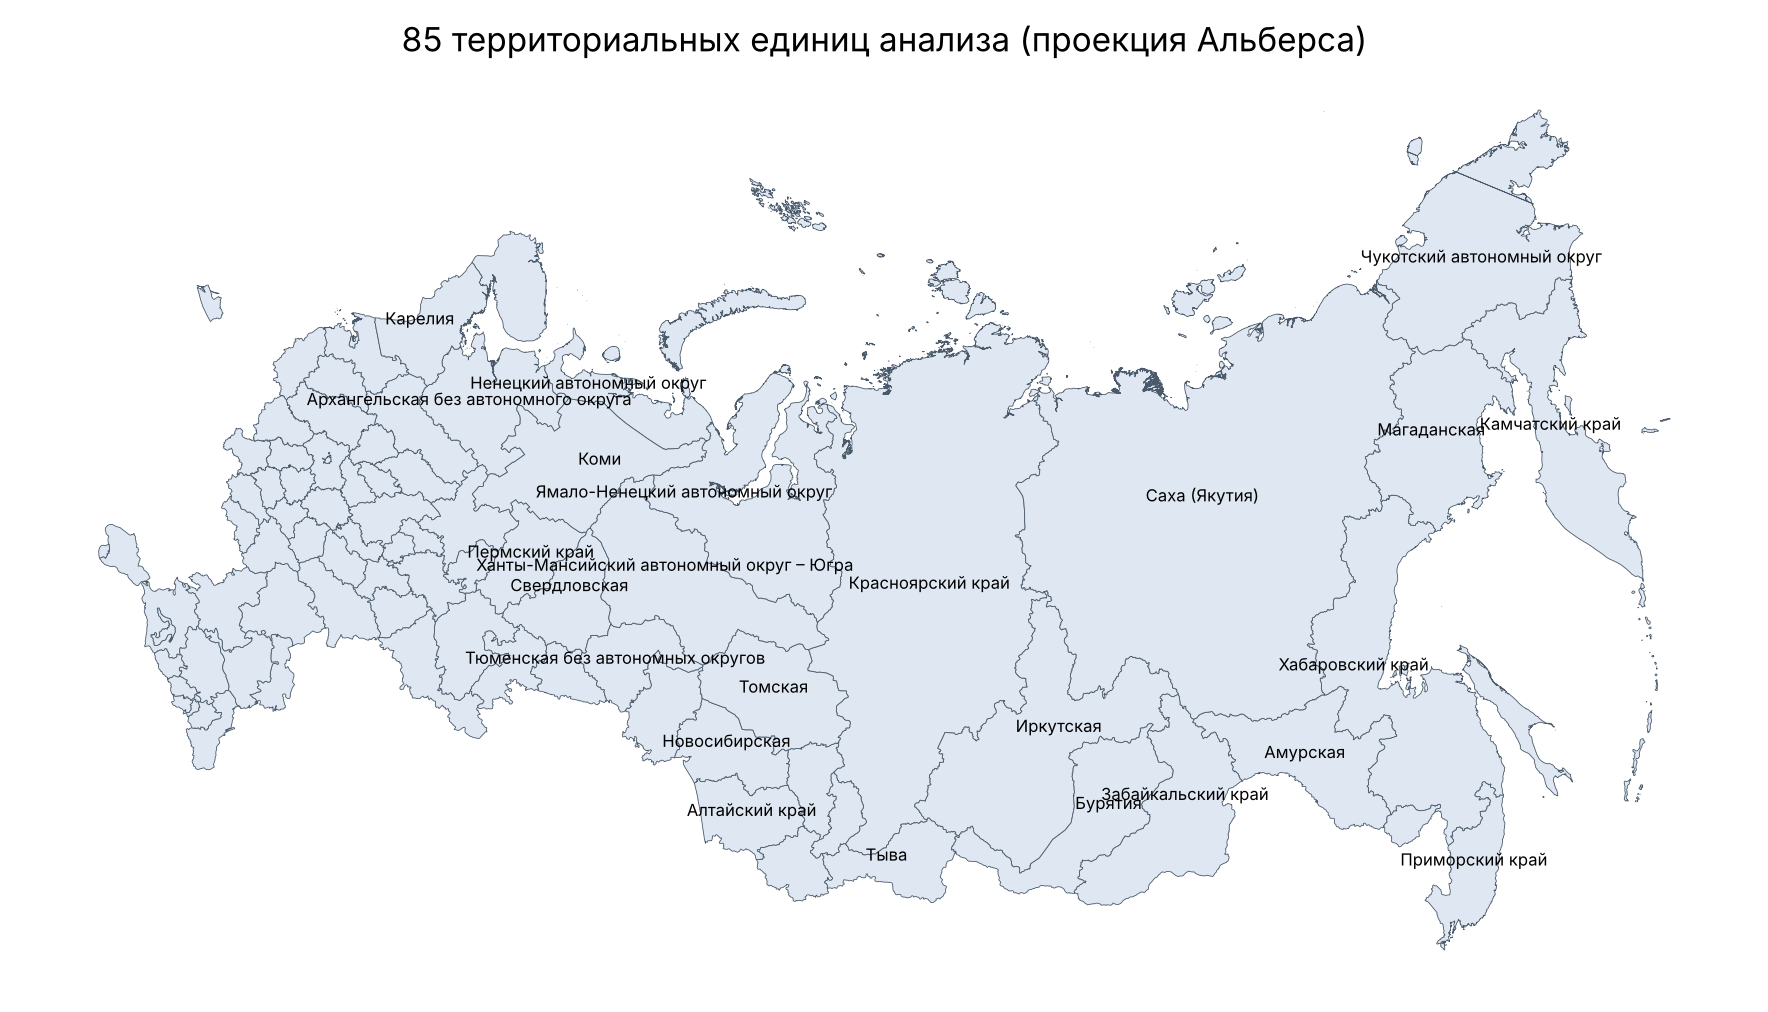

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
simp.plot(ax=ax, color="#dfe7f2", edgecolor="#4a5a6a", linewidth=0.3)
for _, r in simp.iterrows():
    if r.area_km2 > 150_000:
        pt = r.geometry.representative_point()
        ax.annotate(r["name"].replace(" область", "").replace("Республика ", ""), (pt.x, pt.y), fontsize=6, ha="center")
ax.set_axis_off(); ax.set_title("85 территориальных единиц анализа (проекция Альберса)")
plt.savefig(MAPS / "00_units.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Сопоставимость наблюдений
- Все четыре показателя получены по **выборочному** обследованию населения по вопросам использования ИКТ
  (с 2013 г.), то есть содержат ошибку выборки; в малонаселенных регионах (НАО, Чукотка) она больше.
- Единицы различаются: три показателя — доля **домохозяйств** (%), четвертый — доля **населения 15–74 лет** (%).
  Все в процентах, но по разной базе, поэтому перед кластеризацией признаки стандартизуются.
- Доступ к интернету считается «с любого устройства» (примечание Росстата), поэтому он может быть выше доли
  домохозяйств с ПК.

In [13]:
print(gdf[FEATURES].describe().round(1).T)

             count  mean  std   min   25%   50%   75%   max
pc            85.0  69.8  9.4  45.7  64.9  68.3  73.9  95.7
internet      85.0  83.3  6.2  72.0  79.0  82.0  88.1  98.5
broadband     85.0  81.8  6.5  69.5  77.1  80.9  86.3  98.4
daily_users   85.0  79.8  6.7  66.5  74.1  79.6  83.4  94.9
